# Computation of PSF

Histogram dependent on energy and inclination angle theta. Fit with double King

## Imports

In [1]:
import ROOT, glob, os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

## Load data : one file

In [ ]:
dirDir= "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
figPath = dirDir + "figures/"
dataPath = dirDir + "data/"

try :
    os.mkdir(figPath+"PSF")
except FileExistsError:
    pass

figPath = figPath+"PSF/"

df = pd.read_csv(dataPath + "MC_het_filtered_angle.csv")

df = df[df['tt_isHET'] == 1]

In [3]:
df['Etrue'] = df['tt_ekin'] * 1e-3

df = df[df['Etrue'] <= 1e4]

df['theta_True_deg']= df['theta_True']
df['phi_True_deg']= df['phi_True']
df['theta_BestSTK_deg']= df['theta_BestSTK']
df['phi_BestSTK_deg']= df['phi_BestSTK']

In [4]:

print("Full DataFrame loaded:", df.shape)
print(f"Theta ranges from {df['theta_BestSTK'].min()} to {df['theta_BestSTK'].max()} deg")
print(f"Phi ranges from {df['phi_BestSTK'].min()} to {df['phi_BestSTK'].max()} deg")
print(f"phi True ranges from {df['phi_True'].min()} to {df['phi_True'].max()} deg")
print(f"Theta True ranges from {df['theta_True'].min()} to {df['theta_True'].max()} deg")

print(f"Energy ranges from {df['Etrue'].min()} to {df['Etrue'].max()} GeV")

Full DataFrame loaded: (2500072, 12)
Theta ranges from 0.010697885130166 to 59.99906211933338 deg
Phi ranges from -179.9999999999996 to 180.0 deg
phi True ranges from -179.99989495604288 to 179.9998887711325 deg
Theta True ranges from 0.0206227244272939 to 89.97767053951249 deg
Energy ranges from 1.2201475972249158 to 9998.562154091216 GeV


In [5]:
df['theta_BestSTK'] = np.deg2rad(df['theta_BestSTK'])
df['phi_BestSTK'] = np.deg2rad(df['phi_BestSTK'])
df['theta_True'] = np.deg2rad(df['theta_True'])
df['phi_True'] = np.deg2rad(df['phi_True'])

df = df[(df['theta_True'] > 1e-7) & (df['theta_BestSTK'] > 1e-7)]

## Explore branches

In [6]:
print("Full DataFrame pre-processed:", df.shape)

print(f"Theta ranges from {df['theta_BestSTK'].min()} to {df['theta_BestSTK'].max()} rad")
print(f"Phi ranges from {df['phi_BestSTK'].min()} to {df['phi_BestSTK'].max()} rad")
print(f"phi True ranges from {df['phi_True'].min()} to {df['phi_True'].max()} rad")
print(f"Theta True ranges from {df['theta_True'].min()} to {df['theta_True'].max()} rad")

print(f"Energy ranges from {df['Etrue'].min()} to {df['Etrue'].max()} GeV")

Full DataFrame pre-processed: (2500072, 12)
Theta ranges from 0.00018671331852153887 to 1.0471811820909744 rad
Phi ranges from -3.1415926535897865 to 3.141592653589793 rad
phi True ranges from -3.1415908202268823 to 3.1415907122798323 rad
Theta True ranges from 0.00035993444198774053 to 1.5704066041891955 rad
Energy ranges from 1.2201475972249158 to 9998.562154091216 GeV


## Compute angular error 

In [7]:

def angular_error(theta_true, phi_true, theta_reco, phi_reco):

    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # # Compute dot product and then angle between vectors
    dot = np.sum(v_true * v_reco, axis=-1)
    mask = np.abs(dot) > 1
    if np.any(mask):
        print(f"ERROR: Found {np.sum(mask)} dot products not in [-1, 1]")
        print("Examples:", dot[mask][:5])  # print first 5 bad values

    angle_rad = np.arccos(dot)

    # delta_v = v_true - v_reco
    # delta_v_norm = np.linalg.norm(delta_v, axis=-1)

    return angle_rad

def angular_error_2(theta_true, phi_true, theta_reco, phi_reco):

    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # # Compute dot product and then angle between vectors
    # dot = np.sum(v_true * v_reco, axis=-1)
    # mask = np.abs(dot) > 1
    # if np.any(mask):
    #     print(f"ERROR: Found {np.sum(mask)} dot products not in [-1, 1]")
    #     print("Examples:", dot[mask][:5])  # print first 5 bad values

    # angle_rad = np.arccos(dot)

    delta_v = v_true - v_reco
    delta_v_norm = np.linalg.norm(delta_v, axis=-1)

    return delta_v_norm

def error_xyz(theta_true, phi_true, theta_reco, phi_reco):
    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # Compute the difference in Cartesian coordinates
    delta_v = v_true - v_reco

    return delta_v

test1 = angular_error(0.2, 0.2, 0.3, 0.4)
test2 = angular_error_2(0.2, 0.2, 0.3, 0.4)
print("Angular error test:", test1)
print("Angular error test 2:", test2)


Angular error test: 0.11110795869098433
Angular error test 2: 0.11105081645279716


In [8]:
df['angular_error'] = angular_error(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])

df['angular_error_degrees'] = df['angular_error'] * 180 / np.pi

# Count outliers
outliers = df[(df['angular_error_degrees'] > 10)]
print("Outliers count:", outliers.shape[0])
print("Outliers proportion : ", outliers.shape[0] / df.shape[0] *100, "%")

df = df[(df['angular_error_degrees'] < 10)].copy()

df['cosTheta'] = np.cos(df['theta_True'])

angular_error_2_test = angular_error_2(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])
angular_error_2_test = angular_error_2_test * 180 / np.pi

diff_angular_errors = df["angular_error_degrees"] - angular_error_2_test
print("Mean angular error difference:", diff_angular_errors.mean())
print("Median angular error difference:", diff_angular_errors.median())
print("Max angular error difference:", diff_angular_errors.max())
print("Min angular error difference:", diff_angular_errors.min())
print("Standard deviation angular error difference:", diff_angular_errors.std())
print("Maximum angular error method 1:", df["angular_error_degrees"].max())
print("Maximum angular error method 2:", angular_error_2_test.max())
print("Minimum angular error method 1:", df["angular_error_degrees"].min())
print("Minimum angular error method 2:", angular_error_2_test.min())

Outliers count: 34207
Outliers proportion :  1.3682405946708736 %
Mean angular error difference: 7.151059018972245e-05
Median angular error difference: 1.4729495012577587e-08
Max angular error difference: 0.01268668317059607
Min angular error difference: -3.671309988927552e-09
Standard deviation angular error difference: 0.0006052531195790237
Maximum angular error method 1: 9.999769450072845
Maximum angular error method 2: 9.98708276690225
Minimum angular error method 1: 2.7025678491239083e-05
Minimum angular error method 2: 2.7012573558005016e-05


## Study potential biases in xyz

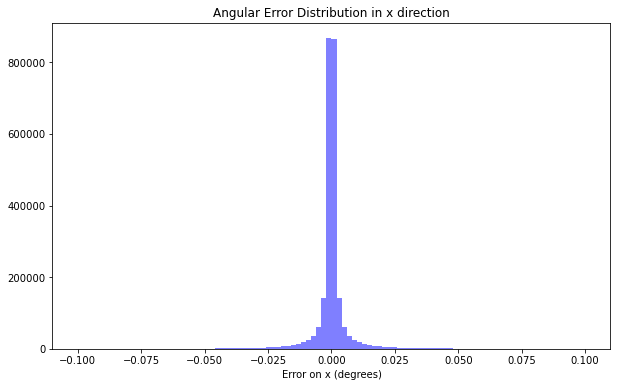

In [9]:
errors_xyz = error_xyz(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])

# Plot histograms of the angular errors
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 0], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='blue')
plt.title('Angular Error Distribution in x direction')
plt.xlabel('Error on x (degrees)')
plt.show()


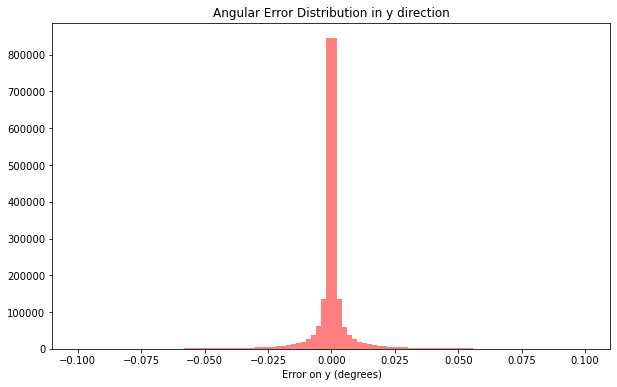

In [10]:
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 1], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='red')
plt.title('Angular Error Distribution in y direction')
plt.xlabel('Error on y (degrees)')
plt.show()


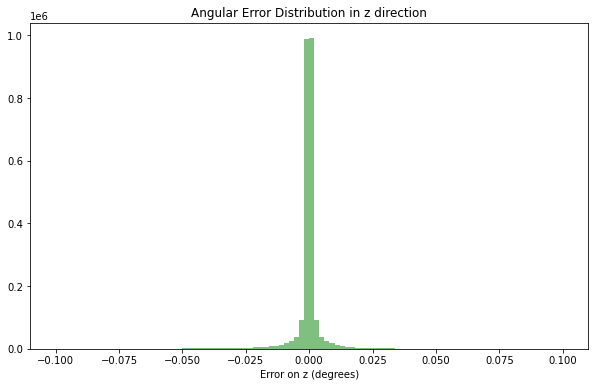

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 2], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='green')
plt.title('Angular Error Distribution in z direction')
plt.xlabel('Error on z (degrees)')
plt.show()


## Study error on theta and phi

In [12]:
theta_diff = df['theta_BestSTK'] - df['theta_True']
phi_diff = df['phi_BestSTK'] - df['phi_True']


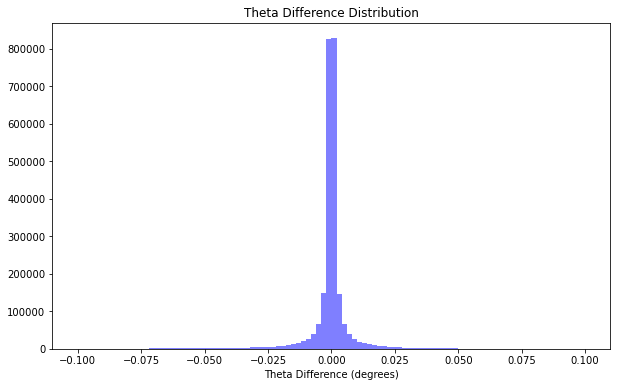

In [13]:
plt.figure(figsize=(10, 6))
plt.hist(theta_diff, bins=100, range=(-0.1, 0.1), alpha=0.5, label='Theta Difference', color='blue')
plt.title('Theta Difference Distribution')
plt.xlabel('Theta Difference (degrees)')
plt.show()


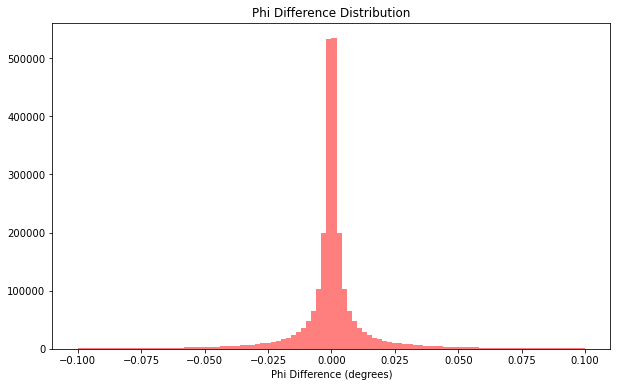

In [14]:
plt.figure(figsize=(10, 6))
plt.hist(phi_diff, bins=100, range=(-0.1, 0.1), alpha=0.5, label='Phi Difference', color='red')
plt.title('Phi Difference Distribution')
plt.xlabel('Phi Difference (degrees)')
plt.show()

## Angular error (absolute value)

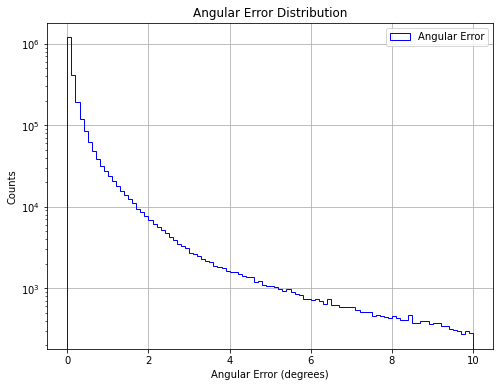

In [15]:
# Plot histogram of angular error
plt.figure(figsize=(8, 6))
plt.hist(df['angular_error_degrees'], bins=100, range=(0, 10), histtype='step', color='blue', label='Angular Error')
plt.xlabel('Angular Error (degrees)')
plt.ylabel('Counts')
plt.title('Angular Error Distribution')
plt.yscale('log')
plt.legend()
plt.grid()
plt.show()

## Plot difference between theta true and reconstructed

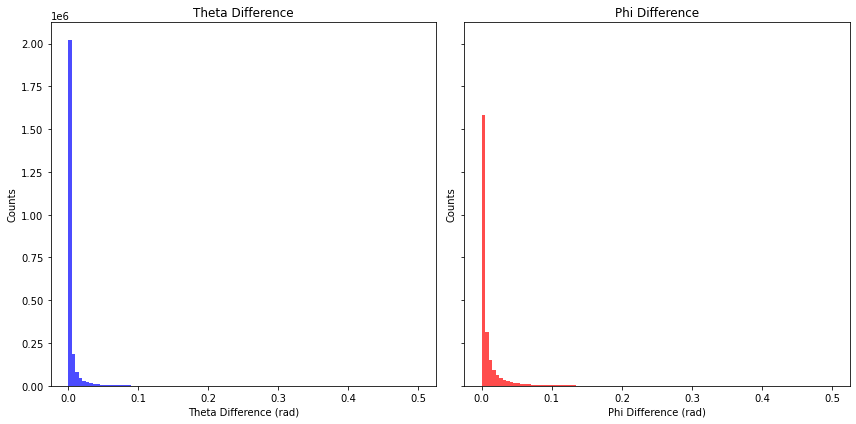

In [16]:
df["thetaDiff"] = df["theta_BestSTK"] - df["theta_True"]
df["phiDiff"] = df["phi_BestSTK"] - df["phi_True"]
df["thetaDiff"] = df["thetaDiff"].abs()
df["phiDiff"] = df["phiDiff"].abs()

# Plot histograms of the differences
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["thetaDiff"], bins=100, range=(0, 0.5), color='blue', alpha=0.7)
ax[0].set_title("Theta Difference")
ax[0].set_xlabel("Theta Difference (rad)")
ax[0].set_ylabel("Counts")
ax[1].hist(df["phiDiff"], bins=100, range=(0, 0.5), color='red', alpha=0.7)
ax[1].set_title("Phi Difference")
ax[1].set_xlabel("Phi Difference (rad)")
ax[1].set_ylabel("Counts")
plt.tight_layout()
plt.show()

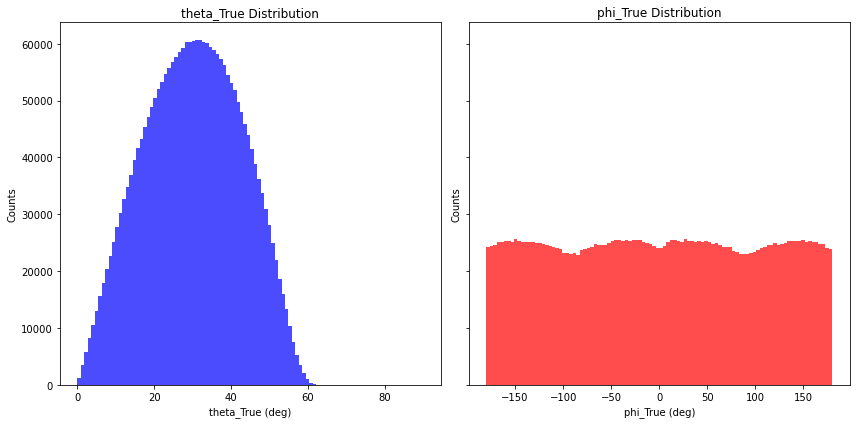

In [18]:
# Plot the distribution of theta_True and phi_True
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["theta_True_deg"], bins=100, range=(0, 90), color='blue', alpha=0.7)
ax[0].set_title("theta_True Distribution")
ax[0].set_xlabel("theta_True (deg)")
ax[0].set_ylabel("Counts")
ax[1].hist(df["phi_True_deg"], bins=100, range=(-180, 180), color='red', alpha=0.7)
ax[1].set_title("phi_True Distribution")
ax[1].set_xlabel("phi_True (deg)")
ax[1].set_ylabel("Counts")
plt.tight_layout()
plt.show()

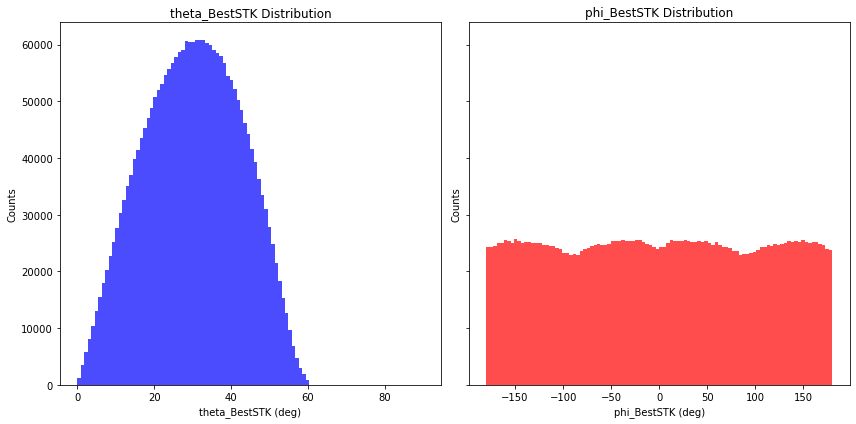

In [19]:
# Plot the distribution of theta_BestT and phi_BestT
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["theta_BestSTK_deg"], bins=100, range=(0, 90), color='blue', alpha=0.7)
ax[0].set_title("theta_BestSTK Distribution")
ax[0].set_xlabel("theta_BestSTK (deg)")
ax[0].set_ylabel("Counts")
ax[1].hist(df["phi_BestSTK_deg"], bins=100, range=(-180,180), color='red', alpha=0.7)
ax[1].set_title("phi_BestSTK Distribution")
ax[1].set_xlabel("phi_BestSTK (deg)")
ax[1].set_ylabel("Counts")
plt.tight_layout()
plt.show()

In [20]:

bins = np.logspace(np.log10(0.01), np.log10(5), 100)  # from 0.01° to 5°, 100 bins

# Compute histogram
counts, bin_edges = np.histogram(df['angular_error_degrees'], bins=bins)

# Compute bin centers
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])  # geometric mean for log bins

density = counts / np.sum(counts)  # normalize to get density


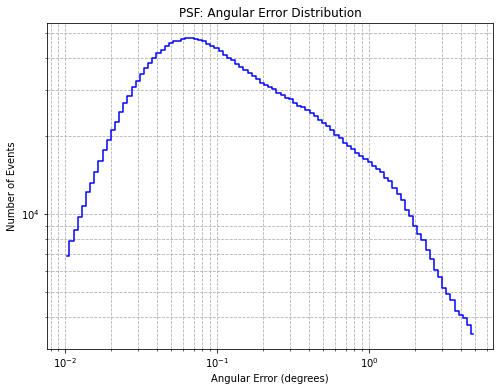

In [21]:

plt.figure(figsize=(8,6))
plt.plot(bin_centers, counts, drawstyle='steps-mid', color='blue')
plt.xscale('log')  # <- LOG X-AXIS for log bins
plt.yscale('log')  # <- optional: LOG Y-AXIS
plt.xlabel('Angular Error (degrees)')
plt.ylabel('Number of Events')
plt.title('PSF: Angular Error Distribution')
plt.grid(True, which="both", ls="--")
plt.show()


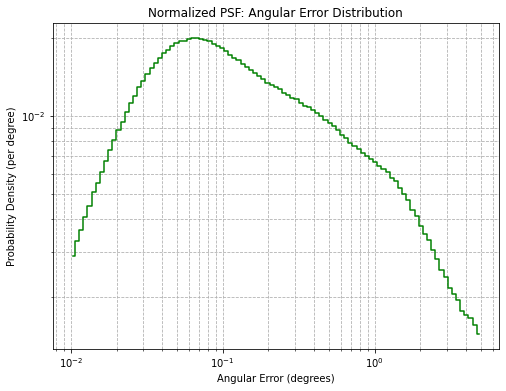

In [22]:

plt.figure(figsize=(8,6))
plt.plot(bin_centers, density, drawstyle='steps-mid', color='green')
plt.xscale('log')  # <- LOG X-AXIS for log bins
plt.yscale('log')  # <- optional: LOG Y-AXIS
plt.xlabel('Angular Error (degrees)')
plt.ylabel('Probability Density (per degree)')
plt.title('Normalized PSF: Angular Error Distribution')
plt.grid(True, which="both", ls="--")
plt.show()


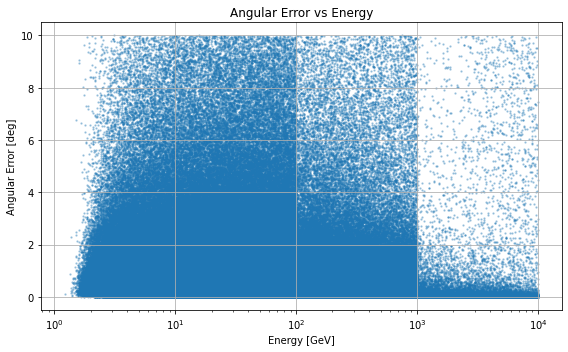

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Etrue'], df['angular_error_degrees'], s=2, alpha=0.3)
plt.xscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Angular Error [deg]")
plt.title("Angular Error vs Energy")
plt.grid(True)
plt.tight_layout()
plt.show()

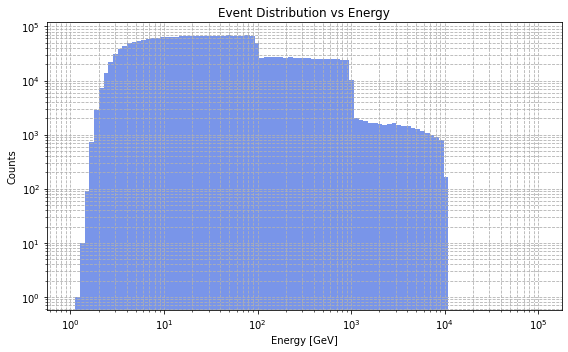

In [24]:
plt.figure(figsize=(8, 5))
plt.hist(df['Etrue'], bins=np.logspace(np.log10(1), np.log10(1e5), 100), color='royalblue', alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Counts")
plt.title("Event Distribution vs Energy")
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()

## Bin by Energy and theta

In [25]:
Emin = 1
Emax = 1e4
n_E_bins = 8
E_bins_edge = np.logspace(np.log10(Emin), np.log10(Emax), n_E_bins + 1)
E_bins_center = np.sqrt(E_bins_edge[:-1] * E_bins_edge[1:])

print("E_bins :", E_bins_center)
print("E_bins_edge :", E_bins_edge)

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 5
theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

print("theta_bins :", theta_bins_center)
print("theta_bins_edge :", theta_bins_edge)

print("Emin: ", Emin)
print("Emax: ", Emax)
print("theta_min: ", cos_theta_min)
print("theta_max: ", cos_theta_max)

# Assign bin indices
df['E_bin'] = pd.cut(df['Etrue'], bins=E_bins_edge, labels=False, include_lowest=True)
df['theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin', 'theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin'] = df['E_bin'].astype(int)
df['theta_bin'] = df['theta_bin'].astype(int)


E_bins : [1.77827941e+00 5.62341325e+00 1.77827941e+01 5.62341325e+01
 1.77827941e+02 5.62341325e+02 1.77827941e+03 5.62341325e+03]
E_bins_edge : [1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02 3.16227766e+02 1.00000000e+03 3.16227766e+03
 1.00000000e+04]
theta_bins : [0.55 0.65 0.75 0.85 0.95]
theta_bins_edge : [0.5 0.6 0.7 0.8 0.9 1. ]
Emin:  1
Emax:  10000.0
theta_min:  0.5
theta_max:  1


In [26]:

# Group by (E_bin, theta_bin)
grouped = df.groupby(['E_bin', 'theta_bin'])

def angular_resolution_68(x):
    lower = np.percentile(x, 16)
    upper = np.percentile(x, 84)
    return (upper - lower) / 2

resolution_per_bin = grouped['angular_error_degrees'].apply(
    angular_resolution_68
).reset_index(name='angular_resolution')
print(resolution_per_bin.head())

# Step 4: Merge back into original dataframe
if 'angular_resolution' in df.columns:
    df = df.drop(columns='angular_resolution')
df = df.merge(resolution_per_bin, on=['E_bin', 'theta_bin'], how='left')

   E_bin  theta_bin  angular_resolution
0      0          0            0.678319
1      0          1            0.530029
2      0          2            0.490494
3      0          3            0.433056
4      0          4            0.376540


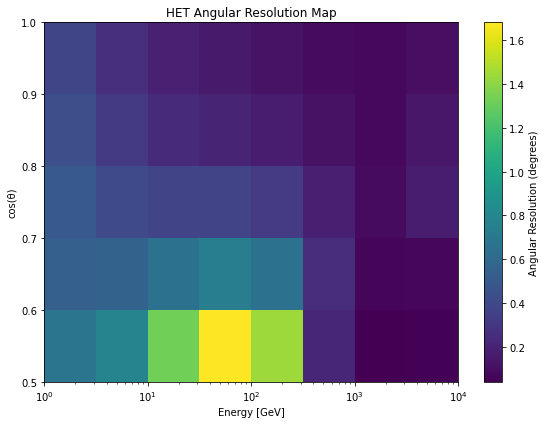

In [27]:
# Build the resolution grid directly
resolution_grid = np.full((n_E_bins, n_theta_bins), np.nan)
for _, row in resolution_per_bin.iterrows():
    resolution_grid[int(row['E_bin']), int(row['theta_bin'])] = row['angular_resolution']


# Prepare edges for pcolormesh
E_edges = E_bins_edge

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
c = ax.pcolormesh(E_edges, theta_bins_edge, resolution_grid.T, shading='auto', cmap='viridis')

# Log scale for energy
ax.set_xscale('log')
ax.set_xlabel("Energy [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("HET Angular Resolution Map")

# Colorbar
cb = fig.colorbar(c, ax=ax)
cb.set_label("Angular Resolution (degrees)")

plt.tight_layout()
fig.savefig(figPath+"resolutionMap_HET.png")
plt.show()


In [28]:
# # Plot angular_deviation for all 20 E, theta bins
# # Determine subplot grid size
# n_rows = n_E_bins
# n_cols = n_theta_bins

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
# fig.suptitle("Angular Deviation in Each (E_bin, θ_bin)", fontsize=16)

# # Plot each bin
# for i in range(n_E_bins):
#     for j in range(n_theta_bins):
#         ax = axes[i, j]
#         subset = df[(df['E_bin'] == i) & (df['theta_bin'] == j)]

#         if not subset.empty:
#             ax.hist(subset['angular_error_degrees'], bins=50, color='royalblue', alpha=0.7, density=True)
#             ax.set_title(f"E_bin={i}, θ_bin={j}", fontsize=9)
#         else:
#             ax.set_visible(False)

#         if i == n_rows - 1:
#             ax.set_xlabel("Angular Deviation (degrees)")
#         if j == 0:
#             ax.set_ylabel("$Density$")
#         ax.set_yscale('log')
#         ax.set_xscale('log')

# plt.tight_layout(rect=[0, 0, 1, 0.96])

## Compute scaled Angular deviation

In [29]:
df['x_p'] = df['angular_error_degrees'] / df["angular_resolution"]

In [30]:
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
# fig.suptitle("Scaled Angular Deviation in Each (E_bin, θ_bin)", fontsize=16)

# # Plot each bin
# for i in range(n_E_bins):
#     for j in range(n_theta_bins):
#         ax = axes[i, j]
#         subset = df[(df['E_bin'] == i) & (df['theta_bin'] == j)]

#         if not subset.empty:
#             ax.hist(subset['x_p'], bins=50, color='royalblue', alpha=0.7, density=True)
#             ax.set_title(f"E_bin={i}, θ_bin={j}", fontsize=9)
#         else:
#             ax.set_visible(False)

#         if i == n_rows - 1:
#             ax.set_xlabel("Scaled Angular Deviation $x_p$")
#         if j == 0:
#             ax.set_ylabel("$Density$")
#         ax.set_yscale('log')
#         ax.set_xscale('log')

# plt.tight_layout(rect=[0, 0, 1, 0.96])
# plt.show()

## Fit with double king

In [31]:
from scipy.stats import chi2

def king(xp, sigma, gamma):
    factor1 = 1/(2*np.pi*sigma*sigma)
    factor2 = (1 - 1/gamma)
    factor3 = (1 + 0.5*(1/gamma)*((xp/sigma)**2))**(-gamma)

    return factor1 * factor2 * factor3

def x_king(xp, sigma, gamma):
    return xp * king(xp, sigma, gamma)


def doubleKing(xp, A, F, sigma_c, gamma_c, sigma_t, gamma_t) :

    return A *(F * x_king(xp, sigma_c, gamma_c) + (1-F) * x_king(xp, sigma_t, gamma_t))

def chisq(data, model, error, dofs):
    residuals = np.abs(data - model)
    chi_squared = np.sum((residuals)**2 / (error**2))
    p_value = 1 - chi2.cdf(chi_squared, dofs)
    return chi_squared, p_value

In [32]:
from scipy.optimize import curve_fit
# Select a specific bin (E_bin and theta_bin)
E_bin = 0
theta_bin = 0
n_bins = 30
subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin)] 

xpMin = subset["x_p"].min()
xpMax = subset["x_p"].max()
bins = np.logspace(np.log10(xpMin), np.log10(xpMax), n_bins)
counts, bin_edges = np.histogram(subset['x_p'], bins=bins)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_widths = bin_edges[1:] - bin_edges[:-1]
errors = np.sqrt(counts)

# Normalize counts and errors
total = np.sum(counts)
print(f"Total number of counts in subset : {total}")
counts_norm = counts / (bin_centers * total) 
errors_norm = errors / (bin_centers * total)

epsilon = 1e-5
valid = (counts > 5) & (counts_norm > epsilon) & (errors_norm > epsilon)


# ---- Initial guesses ----
A_init = 0.2
F_init = 0.8
gamma_init = 1.2
std = np.std(subset['x_p'])


p0 = [ A_init, # A 
    F_init,        # F
    std, gamma_init,  # sigma_c, gamma_c,
    std, gamma_init   # sigma_t, gamma_t
]

#p0 = [430.72318702228625, 0.0007544318960550428, 0.0743047489922788, 0.999855853967373, 0.28605125531570047, 1.278022587242577]

print(f"Initial parameters : {p0}")

bounds = ([0, 0.5, 0, 1.00001, 0, 1.0001],
          [10, 1, 10, 10, 10, 10]
          )

bin_centers_valid = bin_centers[valid]
counts_norm_valid = counts_norm[valid]
errors_norm_valid = errors_norm[valid]


popt, pcov = curve_fit(
        doubleKing,
        bin_centers_valid,
        counts_norm_valid,
        p0=p0,
        sigma=errors_norm_valid,
        bounds=bounds,
        absolute_sigma=True,
        maxfev=20000
    )

fit_vals = doubleKing(bin_centers_valid, *popt)
fit_vals_counts = fit_vals * (bin_widths[valid] * total)  # Convert back to counts
# Compute chi-squared
ndof = len(bin_centers[valid]) - len(popt)  # number of degrees of freedom
chi_squared, p_val = chisq(counts_norm_valid, fit_vals, errors_norm_valid, ndof)
chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"

Total number of counts in subset : 314
Initial parameters : [0.2, 0.8, 1.8004833319301639, 1.2, 1.8004833319301639, 1.2]


Optimised parameters :  1.4281129181041308 0.6287103315277407 0.23217576953301747 2.270430594007273 1.4725188995136016 4.0910622715338905


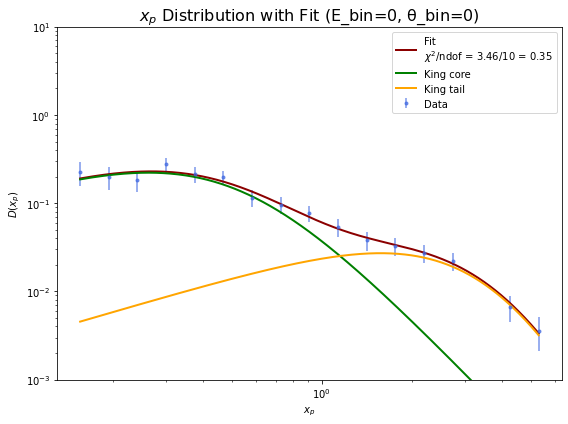

In [33]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(bin_centers_valid, counts_norm_valid, yerr=errors_norm_valid, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)

if popt is not None:
    x_fit = np.linspace(bin_centers_valid[0], bin_centers_valid[-1], 1000)
    y_fit = doubleKing(x_fit, *popt)
    ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}')
    A, F, sigma_c, gamma_c, sigma_t, gamma_t = popt

    y_fit1 = A*(F * x_king(x_fit, sigma_c, gamma_c))
    y_fit2 = A *(1 - F) * x_king(x_fit, sigma_t, gamma_t)

    # Apply the masks to plot only the regions where the conditions are satisfied
    ax.plot(x_fit, y_fit1, color='green', lw=2, label='King core')
    ax.plot(x_fit, y_fit2, color='orange', lw=2, label='King tail')

    print(f"Optimised parameters : ", *popt)

ax.set_title(f"$x_p$ Distribution with Fit (E_bin={E_bin}, θ_bin={theta_bin})", fontsize=16)
ax.set_xlabel("$x_p$")
ax.set_ylabel("$D(x_p)$")
ax.set_yscale('log')
ax.set_xscale("log")
ax.set_ylim(1e-3, 10)
ax.legend()
plt.tight_layout()
plt.show()

## Fit all bins

In [34]:
class EmptyBinException(Exception):
    """Custom exception for empty bins."""
    pass

def get_histogram(subset, bins):
    
    counts, bin_edges = np.histogram(subset['x_p'], bins=bins)

    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    errors = np.sqrt(counts)

    return bin_centers, counts, errors

def get_histogram_normed(subset, bins):

    bin_centers, counts, errors = get_histogram(subset, bins)
    # Normalize counts and errors
    total = np.sum(counts)
    print(f"Total number of counts in subset : {total}")
    counts_norm = counts / (bin_centers * total) 
    errors_norm = errors / (bin_centers * total)

    return bin_centers, counts, errors, counts_norm, errors_norm


def fit_xp_bin(subset, bins) :
    
    bin_centers, counts, errors, counts_norm, errors_norm = get_histogram_normed(subset, bins)

     
    epsilon = 1e-5
    valid = (counts > 5)

    bin_centers_valid = bin_centers[valid]
    counts_norm_valid = counts_norm[valid]
    errors_norm_valid = errors_norm[valid]

    if len(bin_centers_valid) == 0 :
        raise EmptyBinException

    popt, pcov = curve_fit(
            doubleKing,
            bin_centers_valid,
            counts_norm_valid,
            p0=p0,
            sigma=errors_norm_valid,
            bounds=bounds,
            absolute_sigma=True,
            maxfev=20000
        )

    fit_vals = doubleKing(bin_centers_valid, *popt)
    # Compute chi-squared
    ndof = len(bin_centers_valid) - len(popt)  # number of degrees of freedom
    chi_squared, p_val = chisq(counts_norm_valid, fit_vals, errors_norm_valid, ndof)
    
    return popt, chi_squared, p_val, bin_centers_valid, counts_norm_valid, errors_norm_valid

Processing E_bin=0, theta_bin=0
Number of bins generated : 30
Total number of counts in subset : 314
Processing E_bin=0, theta_bin=1
Number of bins generated : 30
Total number of counts in subset : 4113
Processing E_bin=0, theta_bin=2
Number of bins generated : 30
Total number of counts in subset : 13579
Processing E_bin=0, theta_bin=3
Number of bins generated : 30
Total number of counts in subset : 24955
Processing E_bin=0, theta_bin=4
Number of bins generated : 30
Total number of counts in subset : 31278
Processing E_bin=1, theta_bin=0
Number of bins generated : 30
Total number of counts in subset : 8009
Processing E_bin=1, theta_bin=1
Number of bins generated : 30
Total number of counts in subset : 50835
Processing E_bin=1, theta_bin=2
Number of bins generated : 30
Total number of counts in subset : 111059
Processing E_bin=1, theta_bin=3
Number of bins generated : 30
Total number of counts in subset : 161410
Processing E_bin=1, theta_bin=4
Number of bins generated : 30
Total number 

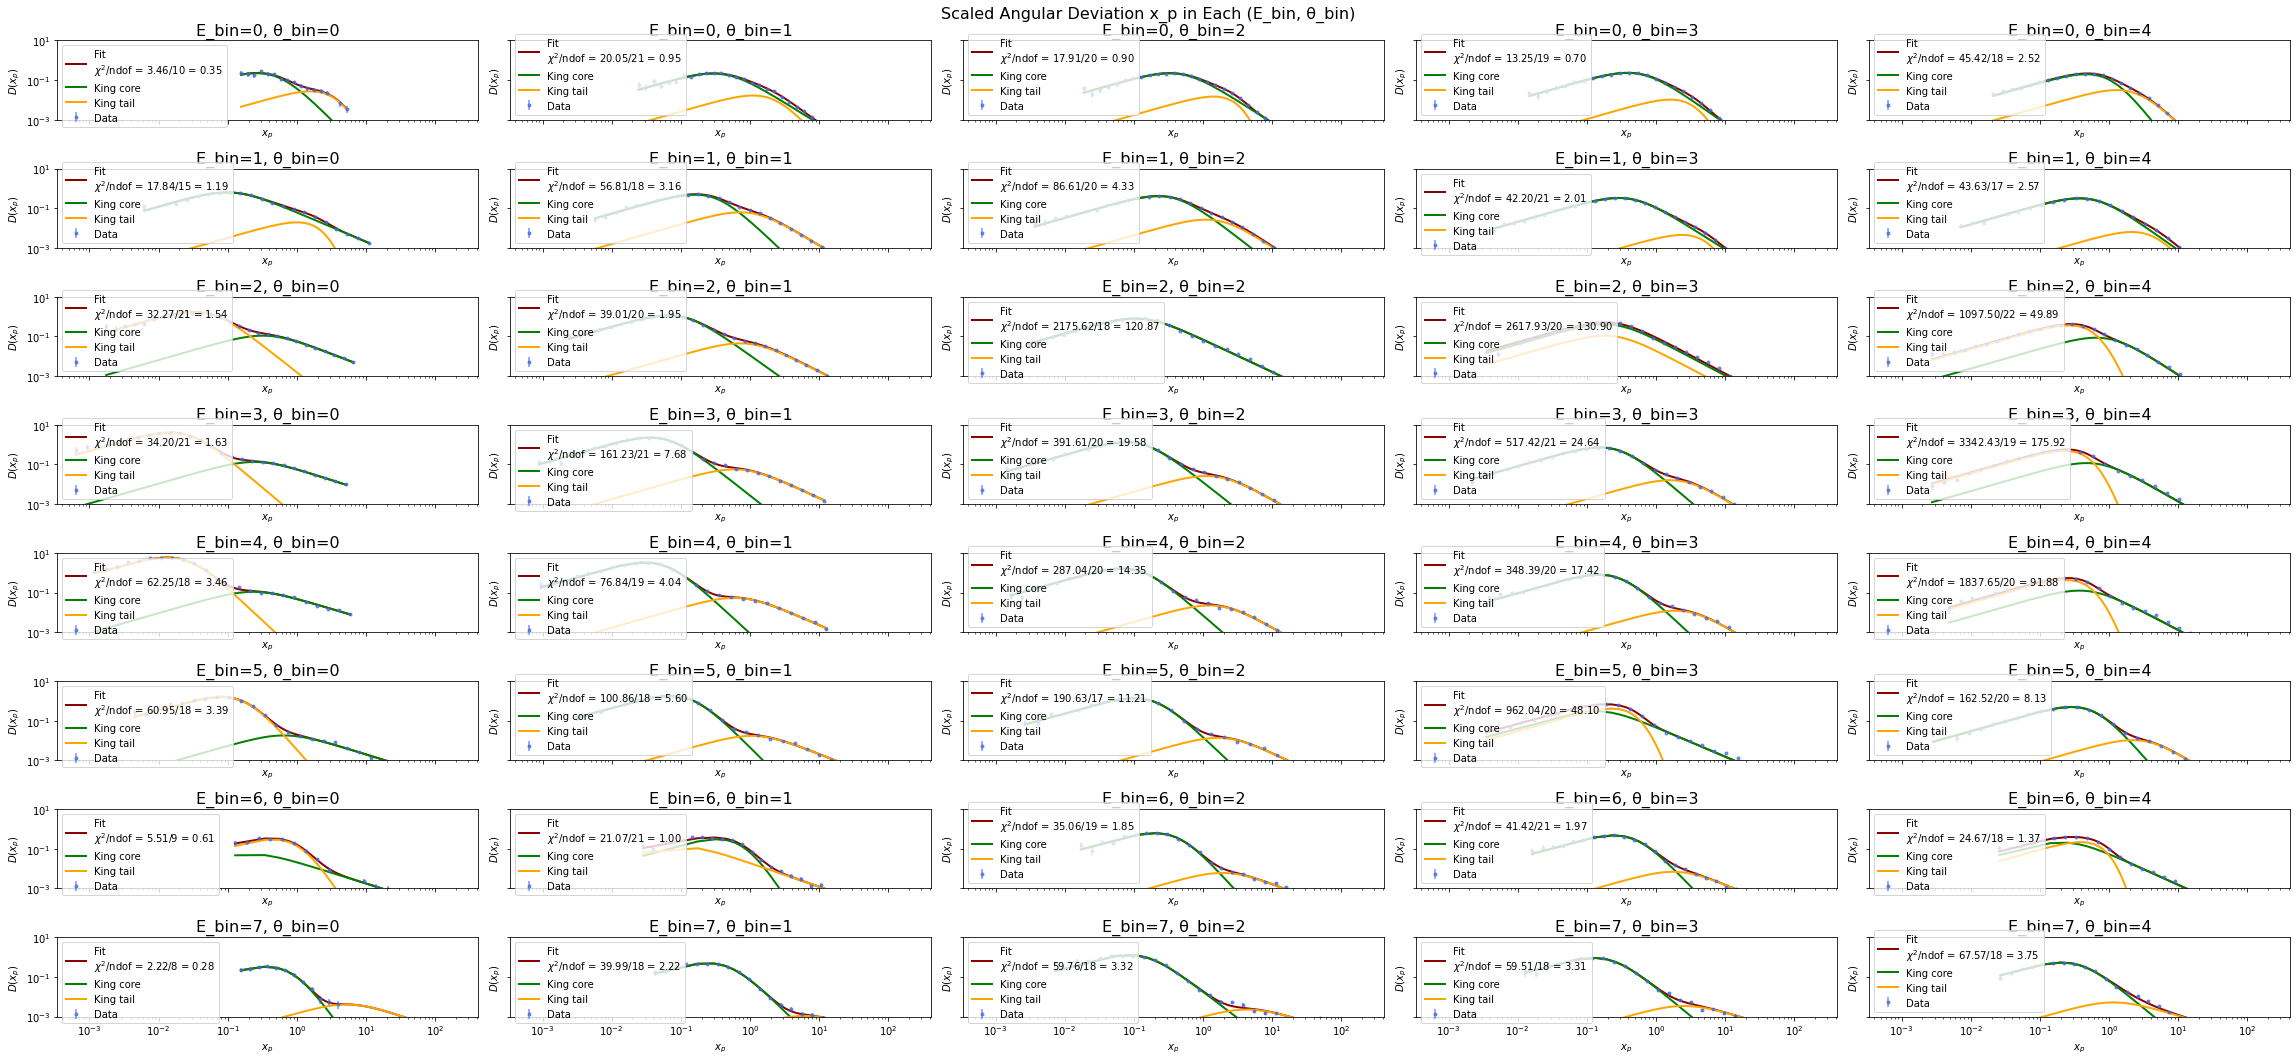

In [35]:
fig, axes = plt.subplots(n_E_bins, n_theta_bins, figsize=(n_E_bins * 4, n_theta_bins * 3), sharex=True, sharey=True)
fig.suptitle("Scaled Angular Deviation x_p in Each (E_bin, θ_bin)", fontsize=16)

for E_bin in range(len(E_bins_center)):
    for theta_bin in range(len(theta_bins_center)):
        print(f'Processing E_bin={E_bin}, theta_bin={theta_bin}')

        subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin)] 
        n_bins = min(30, max(10, len(subset) // 5))
        print(f"Number of bins generated : {n_bins}")

        xpMin = subset["x_p"].min()
        xpMax = subset["x_p"].max()
        bins = np.logspace(np.log10(xpMin), np.log10(xpMax), n_bins)

        ax = axes[E_bin, theta_bin]
        
        ax.set_title(f"E_bin={E_bin}, θ_bin={theta_bin}", fontsize=16)
        ax.set_xlabel("$x_p$")
        ax.set_ylabel("$D(x_p)$")
        ax.set_yscale('log')
        ax.set_xscale("log")
        ax.set_ylim(1e-3, 10)


        try :
            popt, chi_squared, p_val, bin_centers, counts_norm, errors_norm = fit_xp_bin(subset, bins)
            ndof = len(bin_centers) - len(popt)  # number of degrees of freedom
            chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"

        except EmptyBinException as e:
            print(e)
            popt = None
            bin_centers, counts, errors, counts_norm, errors_norm = get_histogram_normed(subset, bins)

        ax.errorbar(bin_centers, counts_norm, yerr=errors_norm, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)


        if popt is not None: 
            
            x_fit = np.linspace(bin_centers[0], bin_centers[-1], 1000)
            y_fit = doubleKing(x_fit, *popt)

            ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}')
            A, F, sigma_c, gamma_c, sigma_t, gamma_t = popt

            y_fit1 = A*(F * x_king(x_fit, sigma_c, gamma_c))
            y_fit2 = A *(1 - F) * x_king(x_fit, sigma_t, gamma_t)

            # Apply the masks to plot only the regions where the conditions are satisfied
            ax.plot(x_fit, y_fit1, color='green', lw=2, label='King core')
            ax.plot(x_fit, y_fit2, color='orange', lw=2, label='King tail')

            
            ax.legend()

fig.tight_layout()
fig.savefig(figPath+"xp_HET_fits_allbins.png")

plt.show()
            